# TileUp — Estudio de escalabilidad

Este cuaderno **no corre los agentes**: solo lee `resultados.csv`. Así el cálculo pesado es
reproducible desde la terminal y aquí solo se analiza y se grafica.

Orden sugerido: correr la batería → abrir este cuaderno → *Run All*.

Cada punto de las gráficas es la **media entre semillas** y la barra es la **desviación estándar**.

In [12]:
import os, sys

# El cuaderno vive en escalabilidad/; trabajamos desde la raíz del repositorio
if os.path.basename(os.getcwd()) == "escalabilidad":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from escalabilidad import graficas as g

# Cambie esta ruta si guardó los resultados en otra carpeta
RUTA_CSV = "escalabilidad/resultados/resultados.csv"
if not os.path.exists(RUTA_CSV):
    RUTA_CSV = "escalabilidad/resultados_rapida/resultados.csv"
    print("No está la batería completa; uso la rápida:", RUTA_CSV)

df = g.cargar(RUTA_CSV)
pd.set_option("display.width", 160)
print(f"{len(df)} corridas leídas de {RUTA_CSV}")

96 corridas leídas de escalabilidad/resultados/resultados.csv


## 1. Qué se corrió y si las soluciones son legales

In [13]:
print("N:", sorted(df.N.unique()), "| K:", sorted(df.K.unique()),
      "| semillas:", sorted(df.semilla.unique()), "| límite:", df.limite_s.max(), "s")
print("M por N:", dict(df.groupby("N").M.first()))
print("Corridas por agente:", dict(df.agente.value_counts()))
print("Soluciones ilegales:", int((df.legal == 0).sum()))
print("Corridas que excedieron el límite:", int(df.excedio_limite.sum()))
df.groupby(["agente", "estado"]).size().unstack(fill_value=0)

N: [np.int64(4), np.int64(6), np.int64(8), np.int64(10)] | K: [np.int64(4), np.int64(8), np.int64(12), np.int64(16)] | semillas: [np.int64(1), np.int64(2), np.int64(3)] | límite: 10.0 s
M por N: {4: np.int64(32), 6: np.int64(72), 8: np.int64(128), 10: np.int64(200)}
Corridas por agente: {'busqueda': np.int64(48), 'evolutivo': np.int64(48)}
Soluciones ilegales: 0
Corridas que excedieron el límite: 0


estado,frontera_vacia,meta
agente,,
busqueda,2,46
evolutivo,0,48


## 2. Tabla resumen (media ± desviación estándar entre semillas)

`exitos` = semillas que colocaron toda la secuencia dentro del límite;
`cortes` = semillas en que la búsqueda se detuvo por tiempo.

In [14]:
res = g.resumen(df)

def pm(m, s, dec=2):
    return f"{m:.{dec}f} ± {0 if pd.isna(s) else s:.{dec}f}"

tabla = pd.DataFrame({
    "agente": res.agente, "N": res.N, "K": res.K, "M": res.M,
    "colocadas": [pm(m, s, 1) for m, s in zip(res.colocadas_media, res.colocadas_std)],
    "ocupadas": [pm(m, s, 1) for m, s in zip(res.ocupadas_media, res.ocupadas_std)],
    "tiempo (s)": [pm(m, s) for m, s in zip(res.tiempo_media, res.tiempo_std)],
    "esfuerzo": [pm(m, s, 0) for m, s in zip(res.esfuerzo_media, res.esfuerzo_std)],
    "exitos": res.exitos.astype(str) + "/" + res.semillas.astype(str),
    "cortes": res.cortes_tiempo,
})
tabla

,agente,N,K,M,colocadas,ocupadas,tiempo (s),esfuerzo,exitos,cortes
0,busqueda,4,4,32,32.0 ± 0.0,4.0 ± 0.0,0.00 ± 0.00,32 ± 0,3/3,0
1,busqueda,4,8,32,32.0 ± 0.0,12.7 ± 3.2,0.00 ± 0.00,34 ± 3,3/3,0
2,busqueda,4,12,32,32.0 ± 0.0,15.3 ± 0.6,2.42 ± 2.32,169702 ± 158743,3/3,0
3,busqueda,4,16,32,29.7 ± 4.0,16.0 ± 0.0,3.35 ± 5.58,219983 ± 362018,2/3,0
4,busqueda,6,4,72,72.0 ± 0.0,4.3 ± 0.6,0.01 ± 0.00,72 ± 0,3/3,0
5,busqueda,6,8,72,72.0 ± 0.0,11.0 ± 1.0,0.01 ± 0.00,72 ± 0,3/3,0
6,busqueda,6,12,72,72.0 ± 0.0,31.0 ± 5.6,0.61 ± 1.04,26956 ± 46564,3/3,0
7,busqueda,6,16,72,70.7 ± 2.3,34.7 ± 1.2,3.27 ± 5.65,138057 ± 238997,2/3,0
8,busqueda,8,4,128,128.0 ± 0.0,4.7 ± 0.6,0.03 ± 0.00,128 ± 0,3/3,0
9,busqueda,8,8,128,128.0 ± 0.0,14.3 ± 2.3,0.03 ± 0.00,128 ± 0,3/3,0


## 3. ¿Qué parámetro domina el costo?

Tiempo en escala logarítmica. La línea roja punteada es el límite de tiempo: un agente que
toca esa línea dejó de terminar por sí solo y entregó la mejor solución parcial.

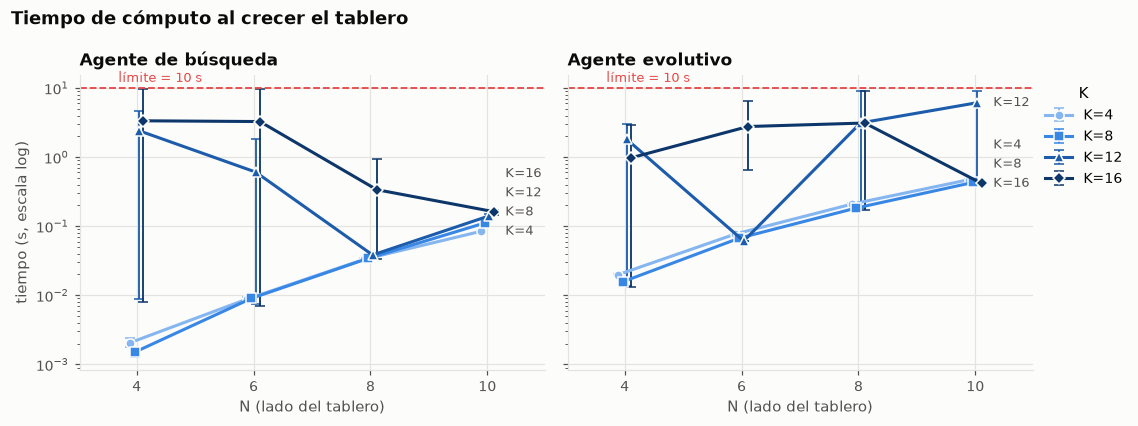

In [15]:
g.figura_tendencia(df, "tiempo_s", x="N", serie="K", log=True, linea_limite=True,
                  etiqueta_y="tiempo (s, escala log)",
                  titulo="Tiempo de cómputo al crecer el tablero")
plt.show()

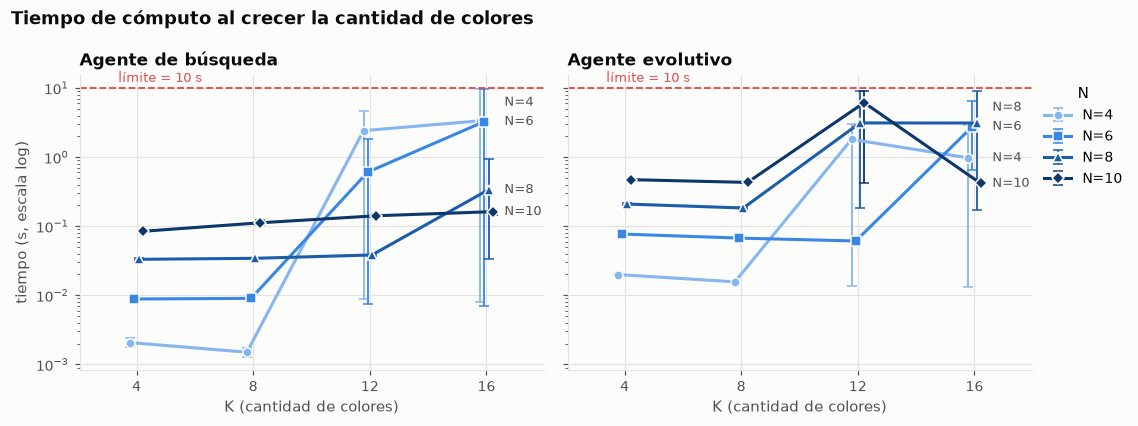

In [16]:
g.figura_tendencia(df, "tiempo_s", x="K", serie="N", log=True, linea_limite=True,
                  etiqueta_y="tiempo (s, escala log)",
                  titulo="Tiempo de cómputo al crecer la cantidad de colores")
plt.show()

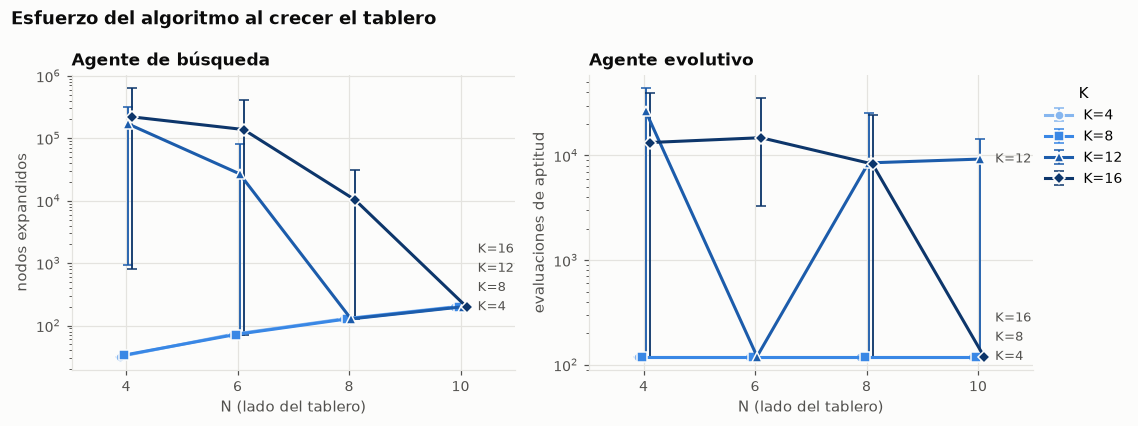

In [17]:
g.figura_tendencia(df, "esfuerzo", x="N", serie="K", log=True, compartir_y=False,
                  titulo="Esfuerzo del algoritmo al crecer el tablero")
plt.show()

## 4. ¿En qué punto la búsqueda deja de terminar dentro del límite?

Cada celda dice en cuántas semillas el agente colocó **toda** la secuencia sin pasarse del
límite; en la búsqueda también se indica cuántas se cortaron por tiempo.

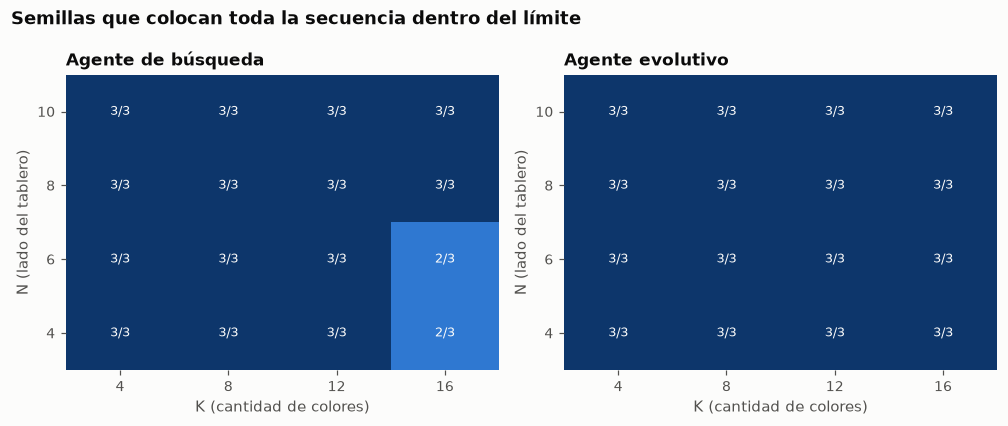

In [18]:
g.figura_mapa_limite(df)
plt.show()

## 5. Calidad de la solución en ese mismo régimen

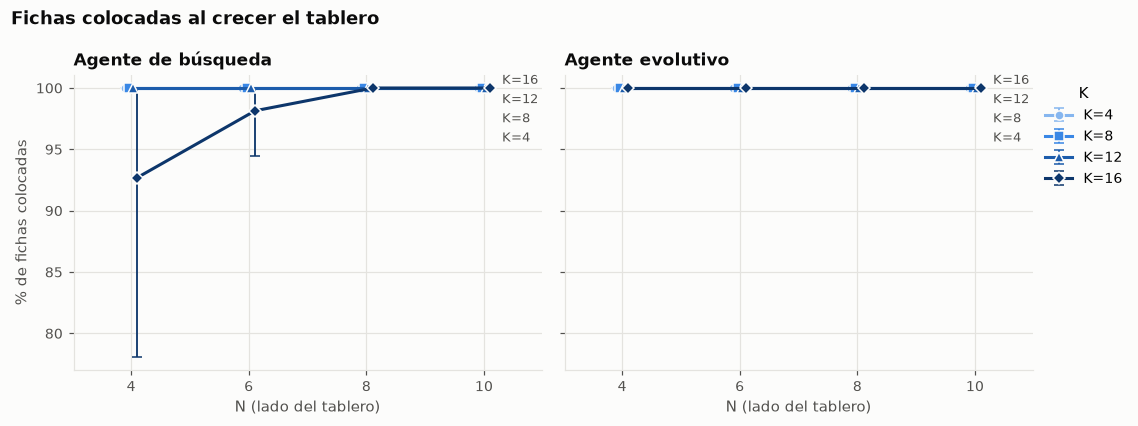

In [19]:
g.figura_tendencia(df, "pct_colocadas", x="N", serie="K",
                  etiqueta_y="% de fichas colocadas",
                  titulo="Fichas colocadas al crecer el tablero")
plt.show()

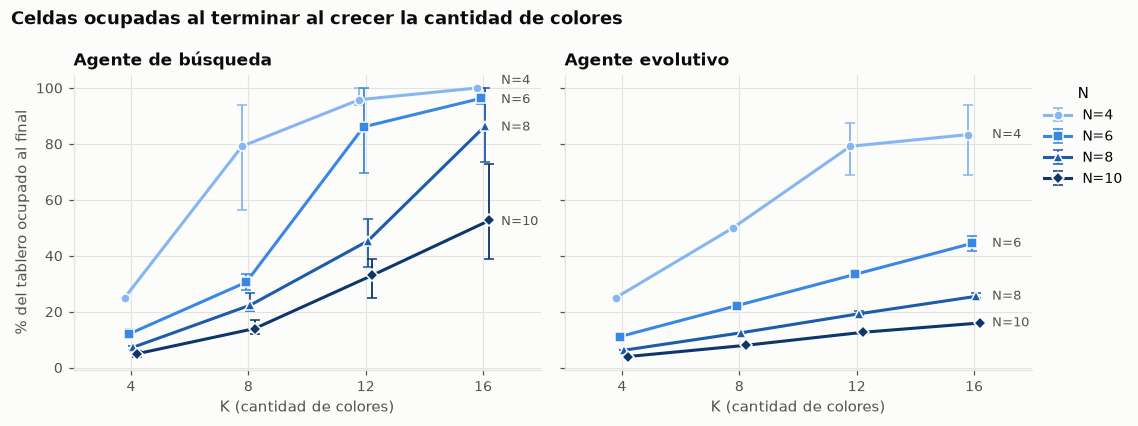

In [20]:
g.figura_tendencia(df, "pct_ocupadas", x="K", serie="N",
                  etiqueta_y="% del tablero ocupado al final",
                  titulo="Celdas ocupadas al terminar al crecer la cantidad de colores")
plt.show()

## 6. Lectura automática

Cifras calculadas a partir del CSV para apoyar la redacción del informe. **No reemplazan la
lectura**: el informe debe explicar *por qué* ocurre cada tendencia (factor de ramificación,
tamaño del espacio de estados, cómo cambia la dificultad al haber más colores que celdas, etc.).

In [21]:
display(Markdown(g.lectura(df)))

- Agente de búsqueda: partiendo de N=4, K=4, llevar N hasta 10 multiplica el tiempo medio por ~41; llevar K hasta 16, por ~1623. Crece más con K (cantidad de colores). Ojo: 2/48 corridas llegan al límite de tiempo, así que en las configuraciones grandes el tiempo ya no mide el costo real (mire el mapa de éxitos y las fichas colocadas).
- Agente evolutivo: partiendo de N=4, K=4, llevar N hasta 10 multiplica el tiempo medio por ~24; llevar K hasta 16, por ~49. Crece más con K (cantidad de colores).
- Primer N en que la búsqueda deja de colocar todo dentro del límite -> K=16: desde N=4 (1/3 semillas).
- De esos fallos, 0 de 2 fueron por agotar el tiempo (el resto, derrota o frontera vacía).
- En esas mismas 2 corridas el evolutivo colocó en promedio el 100.0 % de las fichas, completó la secuencia en 2/2 y tardó 2.01 s de media.
- Soluciones ilegales detectadas al rejugar: 0.

## 7. Informe Resumido

1. **¿Qué parámetro domina el costo de cada agente, N o K?**
- R/ En la búsqueda, domina N, ya que fija el tamaño del problema y K decide si la heurística ayuda o no. En el evolutivo domina K: con pocos colores la población inicial ya llega al óptimo y se detiene enseguida.
2. **¿En qué punto deja la búsqueda de terminar dentro del límite?**
- R/ Hay una tabla por K. Los 22 fallos fueron por tiempo, y cuando se corta entrega muy pocas fichas (4. 7 de 200 en N=10, K=12).
3. **¿Cómo se comporta el evolutivo en ese mismo régimen?**
- R/ Colocó todas las fichas en esas 22 corridas, con 1.90 s de media, y nunca se pasó del límite.
4. **¿Qué pasa con la calidad (celdas ocupadas)?**
- R/ El evolutivo deja igual o menos celdas ocupadas siempre que ambos completan la secuencia. Cuando el de búsqueda ocupo "menos espacio” en tableros grandes se debe solo a que colocó pocas fichas.
5. **Conclusión:**
- R/ La búsqueda solo sirve con N ≤ 4, o hasta N ≤ 8 si K = 4. En general, conviene más el evolutivo por seguridad de trabajar con parámetros de mayor tamaño con menos problemas.

## 8. Guardar las gráficas y el resumen

In [22]:
CARPETA = os.path.join(os.path.dirname(RUTA_CSV), "graficas")
for r in g.guardar_todo(RUTA_CSV, CARPETA):
    print("escrito", r)

escrito escalabilidad/resultados/graficas/tendencia_tiempo_N.png
escrito escalabilidad/resultados/graficas/tendencia_tiempo_K.png
escrito escalabilidad/resultados/graficas/tendencia_esfuerzo_N.png
escrito escalabilidad/resultados/graficas/calidad_colocadas_N.png
escrito escalabilidad/resultados/graficas/calidad_ocupadas_K.png
escrito escalabilidad/resultados/graficas/mapa_limite.png
escrito escalabilidad/resultados/graficas/resumen.csv
